Perform image classification using a pre-trained Vision Transformer (ViT) model and
compare its performance with a CNN model

In [ ]:
import copy
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Subset
from torchvision import datasets, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    ConfusionMatrixDisplay,
)
from tqdm.auto import tqdm
from IPython.display import display

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Enable a GPU runtime for faster execution.")

Device: cpu
Enable a GPU runtime for faster execution.


In [ ]:
SEED = 42
TRAIN_SIZE = 5000
VAL_SIZE = 1000
TEST_SIZE = 2000

BATCH_SIZE = 32
EPOCHS = 15
LEARNING_RATE = 0.001

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize()

set_seed()

In [ ]:
raw_train = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
)

raw_test = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
)

class_names = raw_train.classes

def select_subset(targets, size):
    indices = np.arange(len(targets))

    if size == len(indices):
        return indices

    selected, _ = train_test_split(
        indices,
        train_size=size,
        stratify=targets,
        random_state=SEED,
    )
    return selected

pool_indices = select_subset(
    raw_train.targets,
    TRAIN_SIZE + VAL_SIZE,
)

train_indices, val_indices = train_test_split(
    pool_indices,
    test_size=VAL_SIZE,
    stratify=np.array(raw_train.targets)[pool_indices],
    random_state=SEED,
)

test_indices = select_subset(raw_test.targets, TEST_SIZE)

print("Classes:", class_names)
print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))
print("Test samples:", len(test_indices))

100%|██████████| 170M/170M [1:04:12<00:00, 44.3kB/s]


Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training samples: 5000
Validation samples: 1000
Test samples: 2000


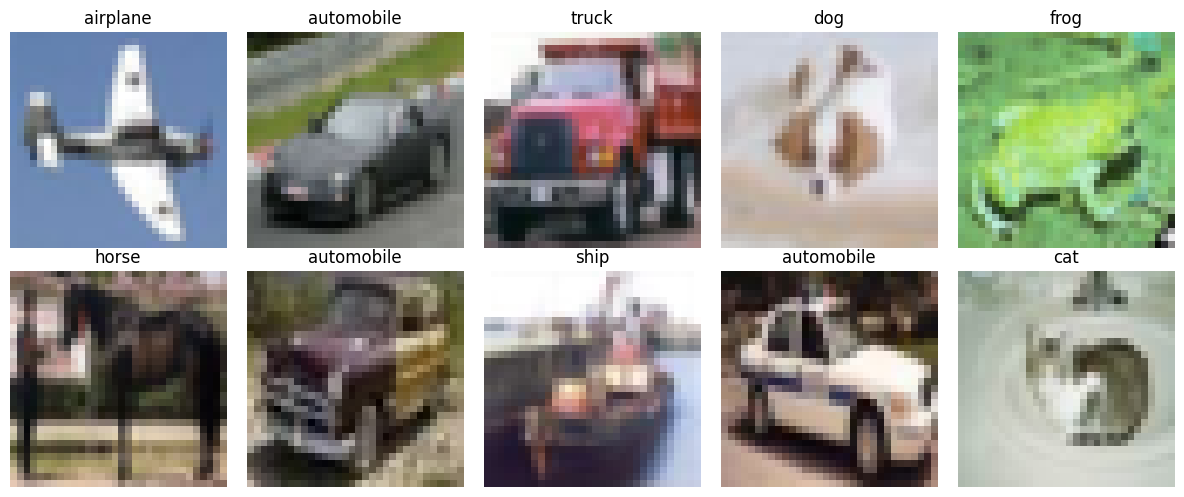

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for ax, index in zip(axes.flat, train_indices[:10]):
    image, label = raw_train[int(index)]

    ax.imshow(image)
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def load_backbone(model_name):
    if model_name == "ViT":
        weights = models.ViT_B_16_Weights.IMAGENET1K_V1
        backbone = models.vit_b_16(weights=weights)

        feature_dim = backbone.heads.head.in_features
        backbone.heads = nn.Identity()

    elif model_name == "CNN":
        weights = models.ResNet18_Weights.IMAGENET1K_V1
        backbone = models.resnet18(weights=weights)

        feature_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()

    else:
        raise ValueError("Unknown model name")

    backbone.requires_grad_(False)
    backbone = backbone.to(device).eval()

    return backbone, weights.transforms(), feature_dim


@torch.inference_mode()
def extract_features(backbone, transform, indices, train, description):
    dataset = datasets.CIFAR10(
        root="./data",
        train=train,
        transform=transform,
        download=False,
    )

    loader = DataLoader(
        Subset(dataset, indices.tolist()),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=(device.type == "cuda"),
    )

    all_features = []
    all_labels = []

    for images, labels in tqdm(loader, desc=description):
        images = images.to(device, non_blocking=True)
        features = backbone(images)

        all_features.append(features.cpu())
        all_labels.append(labels)

    return torch.cat(all_features), torch.cat(all_labels)

In [ ]:
def train_classifier(feature_dim, train_data, val_data, model_name):
    set_seed()

    classifier = nn.Linear(feature_dim, len(class_names)).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        classifier.parameters(),
        lr=LEARNING_RATE,
        weight_decay=1e-4,
    )

    train_loader = DataLoader(
        TensorDataset(*train_data),
        batch_size=256,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )

    val_loader = DataLoader(
        TensorDataset(*val_data),
        batch_size=256,
        shuffle=False,
    )

    history = []
    best_loss = float("inf")
    best_weights = None

    synchronize()
    start = time.perf_counter()

    for epoch in range(EPOCHS):
        classifier.train()

        train_loss = 0.0
        train_correct = 0

        for features, labels in train_loader:
            features = features.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            outputs = classifier(features)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * labels.size(0)
            train_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()

        classifier.eval()

        val_loss = 0.0
        val_correct = 0

        with torch.inference_mode():
            for features, labels in val_loader:
                features = features.to(device)
                labels = labels.to(device)

                outputs = classifier(features)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * labels.size(0)
                val_correct += (
                    outputs.argmax(dim=1) == labels
                ).sum().item()

        train_loss /= len(train_data[1])
        val_loss /= len(val_data[1])

        train_accuracy = train_correct / len(train_data[1])
        val_accuracy = val_correct / len(val_data[1])

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_accuracy": train_accuracy,
            "val_accuracy": val_accuracy,
        })

        if val_loss < best_loss:
            best_loss = val_loss
            best_weights = copy.deepcopy(classifier.state_dict())

        print(
            f"{model_name} | Epoch {epoch + 1:02d}/{EPOCHS} | "
            f"Train accuracy: {train_accuracy:.4f} | "
            f"Validation accuracy: {val_accuracy:.4f}"
        )

    synchronize()
    training_seconds = time.perf_counter() - start

    classifier.load_state_dict(best_weights)

    return classifier.eval(), pd.DataFrame(history), training_seconds

In [ ]:
@torch.inference_mode()
def predict(classifier, features):
    predictions = []

    for batch in features.split(256):
        outputs = classifier(batch.to(device))
        predictions.append(outputs.argmax(dim=1).cpu())

    return torch.cat(predictions).numpy()


@torch.inference_mode()
def measure_speed(backbone, classifier):
    images = torch.randn(
        BATCH_SIZE, 3, 224, 224, device=device
    )

    # Warm up before measuring.
    for _ in range(5):
        classifier(backbone(images))

    synchronize()
    start = time.perf_counter()

    repeats = 20

    for _ in range(repeats):
        classifier(backbone(images))

    synchronize()
    elapsed = time.perf_counter() - start

    return (BATCH_SIZE * repeats) / elapsed

In [ ]:
results = []
histories = {}
predictions = {}

def run_experiment(model_name):
    backbone, transform, feature_dim = load_backbone(model_name)

    synchronize()
    start = time.perf_counter()

    train_data = extract_features(
        backbone, transform, train_indices,
        train=True, description=f"{model_name}: training features",
    )

    val_data = extract_features(
        backbone, transform, val_indices,
        train=True, description=f"{model_name}: validation features",
    )

    synchronize()
    feature_seconds = time.perf_counter() - start

    classifier, history, head_seconds = train_classifier(
        feature_dim,
        train_data,
        val_data,
        model_name,
    )

    test_data = extract_features(
        backbone, transform, test_indices,
        train=False, description=f"{model_name}: test features",
    )

    y_true = test_data[1].numpy()
    y_pred = predict(classifier, test_data[0])

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0,
    )

    images_per_second = measure_speed(backbone, classifier)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Training Time (s)": feature_seconds + head_seconds,
        "Images/Second": images_per_second,
        "Parameters (M)": (
            sum(p.numel() for p in backbone.parameters())
            + sum(p.numel() for p in classifier.parameters())
        ) / 1e6,
    })

    histories[model_name] = history
    predictions[model_name] = y_pred

    print(f"\n{model_name} classification report:\n")
    print(classification_report(
        y_true,
        y_pred,
        labels=list(range(10)),
        target_names=class_names,
        zero_division=0,
    ))

    del backbone, classifier, train_data, val_data, test_data

    if device.type == "cuda":
        torch.cuda.empty_cache()


run_experiment("ViT")

ViT: training features:   0%|          | 0/157 [00:00<?, ?it/s]

ViT: validation features:   0%|          | 0/32 [00:00<?, ?it/s]

ViT | Epoch 01/15 | Train accuracy: 0.7044 | Validation accuracy: 0.9060
ViT | Epoch 02/15 | Train accuracy: 0.9142 | Validation accuracy: 0.9150
ViT | Epoch 03/15 | Train accuracy: 0.9236 | Validation accuracy: 0.9250
ViT | Epoch 04/15 | Train accuracy: 0.9326 | Validation accuracy: 0.9270
ViT | Epoch 05/15 | Train accuracy: 0.9396 | Validation accuracy: 0.9300
ViT | Epoch 06/15 | Train accuracy: 0.9434 | Validation accuracy: 0.9280
ViT | Epoch 07/15 | Train accuracy: 0.9478 | Validation accuracy: 0.9320
ViT | Epoch 08/15 | Train accuracy: 0.9516 | Validation accuracy: 0.9280
ViT | Epoch 09/15 | Train accuracy: 0.9554 | Validation accuracy: 0.9260
ViT | Epoch 10/15 | Train accuracy: 0.9588 | Validation accuracy: 0.9290
ViT | Epoch 11/15 | Train accuracy: 0.9612 | Validation accuracy: 0.9300
ViT | Epoch 12/15 | Train accuracy: 0.9626 | Validation accuracy: 0.9310
ViT | Epoch 13/15 | Train accuracy: 0.9646 | Validation accuracy: 0.9340
ViT | Epoch 14/15 | Train accuracy: 0.9662 | Valida

ViT: test features:   0%|          | 0/63 [00:00<?, ?it/s]


ViT classification report:

              precision    recall  f1-score   support

    airplane       0.93      0.90      0.92       200
  automobile       0.97      0.99      0.98       200
        bird       0.89      0.92      0.90       200
         cat       0.86      0.84      0.85       200
        deer       0.90      0.91      0.91       200
         dog       0.89      0.89      0.89       200
        frog       0.95      0.97      0.96       200
       horse       0.94      0.94      0.94       200
        ship       0.96      0.94      0.95       200
       truck       0.97      0.97      0.97       200

    accuracy                           0.93      2000
   macro avg       0.93      0.93      0.93      2000
weighted avg       0.93      0.93      0.93      2000



In [ ]:
run_experiment("CNN")

In [ ]:
comparison = pd.DataFrame(results).set_index("Model")

display_table = comparison.copy()

metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
]

display_table[metric_columns] *= 100

display(display_table.round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

display_table[["Accuracy", "Macro F1"]].plot.bar(
    ax=axes[0],
    ylim=(0, 100),
    rot=0,
    title="Test Performance",
)
axes[0].set_ylabel("Score (%)")

comparison["Training Time (s)"].plot.bar(
    ax=axes[1],
    rot=0,
    title="Training Time",
    color=["royalblue", "orange"],
)
axes[1].set_ylabel("Seconds")

comparison["Images/Second"].plot.bar(
    ax=axes[2],
    rot=0,
    title="Inference Throughput",
    color=["royalblue", "orange"],
)
axes[2].set_ylabel("Images per second")

plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, history in histories.items():
    axes[0].plot(
        history["epoch"],
        history["train_loss"],
        label=f"{name}: train",
    )
    axes[0].plot(
        history["epoch"],
        history["val_loss"],
        linestyle="--",
        label=f"{name}: validation",
    )

    axes[1].plot(
        history["epoch"],
        history["val_accuracy"] * 100,
        label=name,
    )

axes[0].set_title("Classifier Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")

axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
y_true = np.array(raw_test.targets)[test_indices]

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

for ax, name in zip(axes, ["ViT", "CNN"]):
    ConfusionMatrixDisplay.from_predictions(
        y_true,
        predictions[name],
        labels=list(range(10)),
        display_labels=class_names,
        cmap="Blues",
        xticks_rotation=45,
        colorbar=False,
        ax=ax,
    )
    ax.set_title(f"{name} Confusion Matrix")

plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for i, ax in enumerate(axes.flat):
    image, true_label = raw_test[int(test_indices[i])]

    vit_label = predictions["ViT"][i]
    cnn_label = predictions["CNN"][i]

    ax.imshow(image)
    ax.set_title(
        f"Actual: {class_names[true_label]}\n"
        f"ViT: {class_names[vit_label]}\n"
        f"CNN: {class_names[cnn_label]}",
        fontsize=10,
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
vit_accuracy = comparison.loc["ViT", "Accuracy"]
cnn_accuracy = comparison.loc["CNN", "Accuracy"]

if np.isclose(vit_accuracy, cnn_accuracy):
    print("Both models achieved the same test accuracy.")
else:
    winner = "ViT" if vit_accuracy > cnn_accuracy else "CNN"
    print(f"{winner} achieved higher test accuracy.")

print(f"ViT accuracy: {vit_accuracy:.2%}")
print(f"CNN accuracy: {cnn_accuracy:.2%}")

gap = abs(vit_accuracy - cnn_accuracy) * 100
print(f"Accuracy difference: {gap:.2f} percentage points.")

fastest = comparison["Images/Second"].idxmax()
print(f"Highest measured inference throughput: {fastest}")

print(
    "\nThis experiment compares frozen pretrained features with "
    "trained linear classifiers. Results depend on the dataset, "
    "sample size, training settings, and hardware. The models "
    "have different sizes and computational costs."
)

comparison.to_csv("vit_vs_cnn_results.csv")

from google.colab import files
files.download("vit_vs_cnn_results.csv")